# Feature Engineering and Modelling

---

1. Import packages
2. Load data
3. Modelling

---

## 1. Import packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---
## 2. Load data

In [ ]:
df = pd.read_csv('./data_for_predictions.csv')
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.116900,0.100015,40.606701,...,71,9,1,0,0,0,0,1,0,0


---

## 3. Modelling

We now have a dataset containing features that we have engineered and we are ready to start training a predictive model. Remember, we only need to focus on training a `Random Forest` classifier.

In [ ]:
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

### Data sampling

The first thing we want to do is split our dataset into training and test samples. The reason why we do this, is so that we can simulate a real life situation by generating predictions for our test sample, without showing the predictive model these data points. This gives us the ability to see how well our model is able to generalise to new data, which is critical.

A typical % to dedicate to testing is between 20-30, for this example we will use a 75-25% split between train and test respectively.

In [ ]:
# Make a copy of our data
train_df = df.copy()

# Separate target variable from independent variables
y = df['churn']
X = df.drop(columns=['id', 'churn'])
print(X.shape)
print(y.shape)

(14606, 61)
(14606,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(10954, 61)
(10954,)
(3652, 61)
(3652,)


### Model training

Once again, we are using a `Random Forest` classifier in this example. A Random Forest sits within the category of `ensemble` algorithms because internally the `Forest` refers to a collection of `Decision Trees` which are tree-based learning algorithms. As the data scientist, you can control how large the forest is (that is, how many decision trees you want to include).

The reason why an `ensemble` algorithm is powerful is because of the laws of averaging, weak learners and the central limit theorem. If we take a single decision tree and give it a sample of data and some parameters, it will learn patterns from the data. It may be overfit or it may be underfit, but that is now our only hope, that single algorithm. 

With `ensemble` methods, instead of banking on 1 single trained model, we can train 1000's of decision trees, all using different splits of the data and learning different patterns. It would be like asking 1000 people to all learn how to code. You would end up with 1000 people with different answers, methods and styles! The weak learner notion applies here too, it has been found that if you train your learners not to overfit, but to learn weak patterns within the data and you have a lot of these weak learners, together they come together to form a highly predictive pool of knowledge! This is a real life application of many brains are better than 1.

Now instead of relying on 1 single decision tree for prediction, the random forest puts it to the overall views of the entire collection of decision trees. Some ensemble algorithms using a voting approach to decide which prediction is best, others using averaging. 

As we increase the number of learners, the idea is that the random forest's performance should converge to its best possible solution.

Some additional advantages of the random forest classifier include:

- The random forest uses a rule-based approach instead of a distance calculation and so features do not need to be scaled
- It is able to handle non-linear parameters better than linear based models

On the flip side, some disadvantages of the random forest classifier include:

- The computational power needed to train a random forest on a large dataset is high, since we need to build a whole ensemble of estimators.
- Training time can be longer due to the increased complexity and size of thee ensemble

In [7]:
# Train Random Forest Classifier with 1000 trees for stable ensemble averaging
model = RandomForestClassifier(
    n_estimators=1000,
    criterion='gini',
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print('RandomForestClassifier trained successfully on', X_train.shape[0], 'samples.')

RandomForestClassifier trained successfully on 10954 samples.


### Evaluation

Now let's evaluate how well this trained model is able to predict the values of the test dataset.

#### 1. Why did we choose these evaluation metrics?
In our dataset of `14,606` customers, only `9.72%` (`1,419` customers) actually churned while `90.28%` (`13,187` customers) stayed. In the 25% test set (`3,652` customers), `3,286` are retained (`0`) and `366` churned (`1`).

Because of this severe **class imbalance (~9:1 ratio)**, relying on **Accuracy** alone is misleading: a naive baseline model that simply predicts `0` (no churn) for every single customer would still achieve `89.98%` accuracy (`3286 / 3652`), despite failing to identify a single churning customer.

Therefore, we evaluate the model using a comprehensive set of classification metrics:
- **Confusion Matrix (`TN`, `FP`, `FN`, `TP`):** Breaks down exact counts of correct and incorrect predictions across both classes.
- **Precision ($\frac{TP}{TP + FP}$):** Measures the proportion of predicted churners who actually churn. High precision ensures PowerCo does not waste retention discounts on loyal customers (False Positives).
- **Recall / Sensitivity ($\frac{TP}{TP + FN}$):** Measures the proportion of actual churners that the model successfully catches. In churn prevention, Recall is critical because missing a churning client (False Negative) means losing their entire contract margin.
- **F1-Score:** The harmonic mean of Precision and Recall, providing a balanced single metric for imbalanced classes.
- **ROC-AUC & Precision-Recall AUC:** Evaluate the model's ability to rank-order churn risk across all possible probability thresholds.

In [8]:
# Generate class predictions (default 0.50 cutoff) and predicted churn probabilities
predictions = model.predict(X_test)
proba_predictions = model.predict_proba(X_test)[:, 1]

tn, fp, fn, tp = metrics.confusion_matrix(y_test, predictions).ravel()
print(f'True Negatives (TN):  {tn}')
print(f'False Positives (FP): {fp}')
print(f'False Negatives (FN): {fn}')
print(f'True Positives (TP):  {tp}')

True Negatives (TN):  3283
False Positives (FP): 3
False Negatives (FN): 349
True Positives (TP):  17


In [9]:
# Calculate performance metrics at default threshold (0.50) vs tuned threshold (0.20)
acc = metrics.accuracy_score(y_test, predictions)
prec = metrics.precision_score(y_test, predictions)
rec = metrics.recall_score(y_test, predictions)
f1 = metrics.f1_score(y_test, predictions)
roc_auc = metrics.roc_auc_score(y_test, proba_predictions)
pr_auc = metrics.average_precision_score(y_test, proba_predictions)

print('=== Default Threshold (0.50) Performance ===')
print(f'Accuracy:  {acc:.4f} ({acc*100:.2f}%)')
print(f'Precision: {prec:.4f} ({prec*100:.2f}%)')
print(f'Recall:    {rec:.4f} ({rec*100:.2f}%)')
print(f'F1-Score:  {f1:.4f}')
print(f'ROC-AUC:   {roc_auc:.4f}')
print(f'PR-AUC:    {pr_auc:.4f}')

# Evaluate at a tuned probability threshold of 0.20 to address class imbalance
predictions_tuned = (proba_predictions >= 0.20).astype(int)
tn_t, fp_t, fn_t, tp_t = metrics.confusion_matrix(y_test, predictions_tuned).ravel()
print('\n=== Tuned Threshold (0.20) Performance ===')
print(f'TN={tn_t}, FP={fp_t}, FN={fn_t}, TP={tp_t}')
print(f'Accuracy:  {metrics.accuracy_score(y_test, predictions_tuned):.4f}')
print(f'Precision: {metrics.precision_score(y_test, predictions_tuned):.4f}')
print(f'Recall:    {metrics.recall_score(y_test, predictions_tuned):.4f}')
print(f'F1-Score:  {metrics.f1_score(y_test, predictions_tuned):.4f}')

=== Default Threshold (0.50) Performance ===
Accuracy:  0.9036 (90.36%)
Precision: 0.8500 (85.00%)
Recall:    0.0464 (4.64%)
F1-Score:  0.0881
ROC-AUC:   0.6665
PR-AUC:    0.2779

=== Tuned Threshold (0.20) Performance ===
TN=2922, FP=364, FN=236, TP=130
Accuracy:  0.8357
Precision: 0.2632
Recall:    0.3552
F1-Score:  0.3023


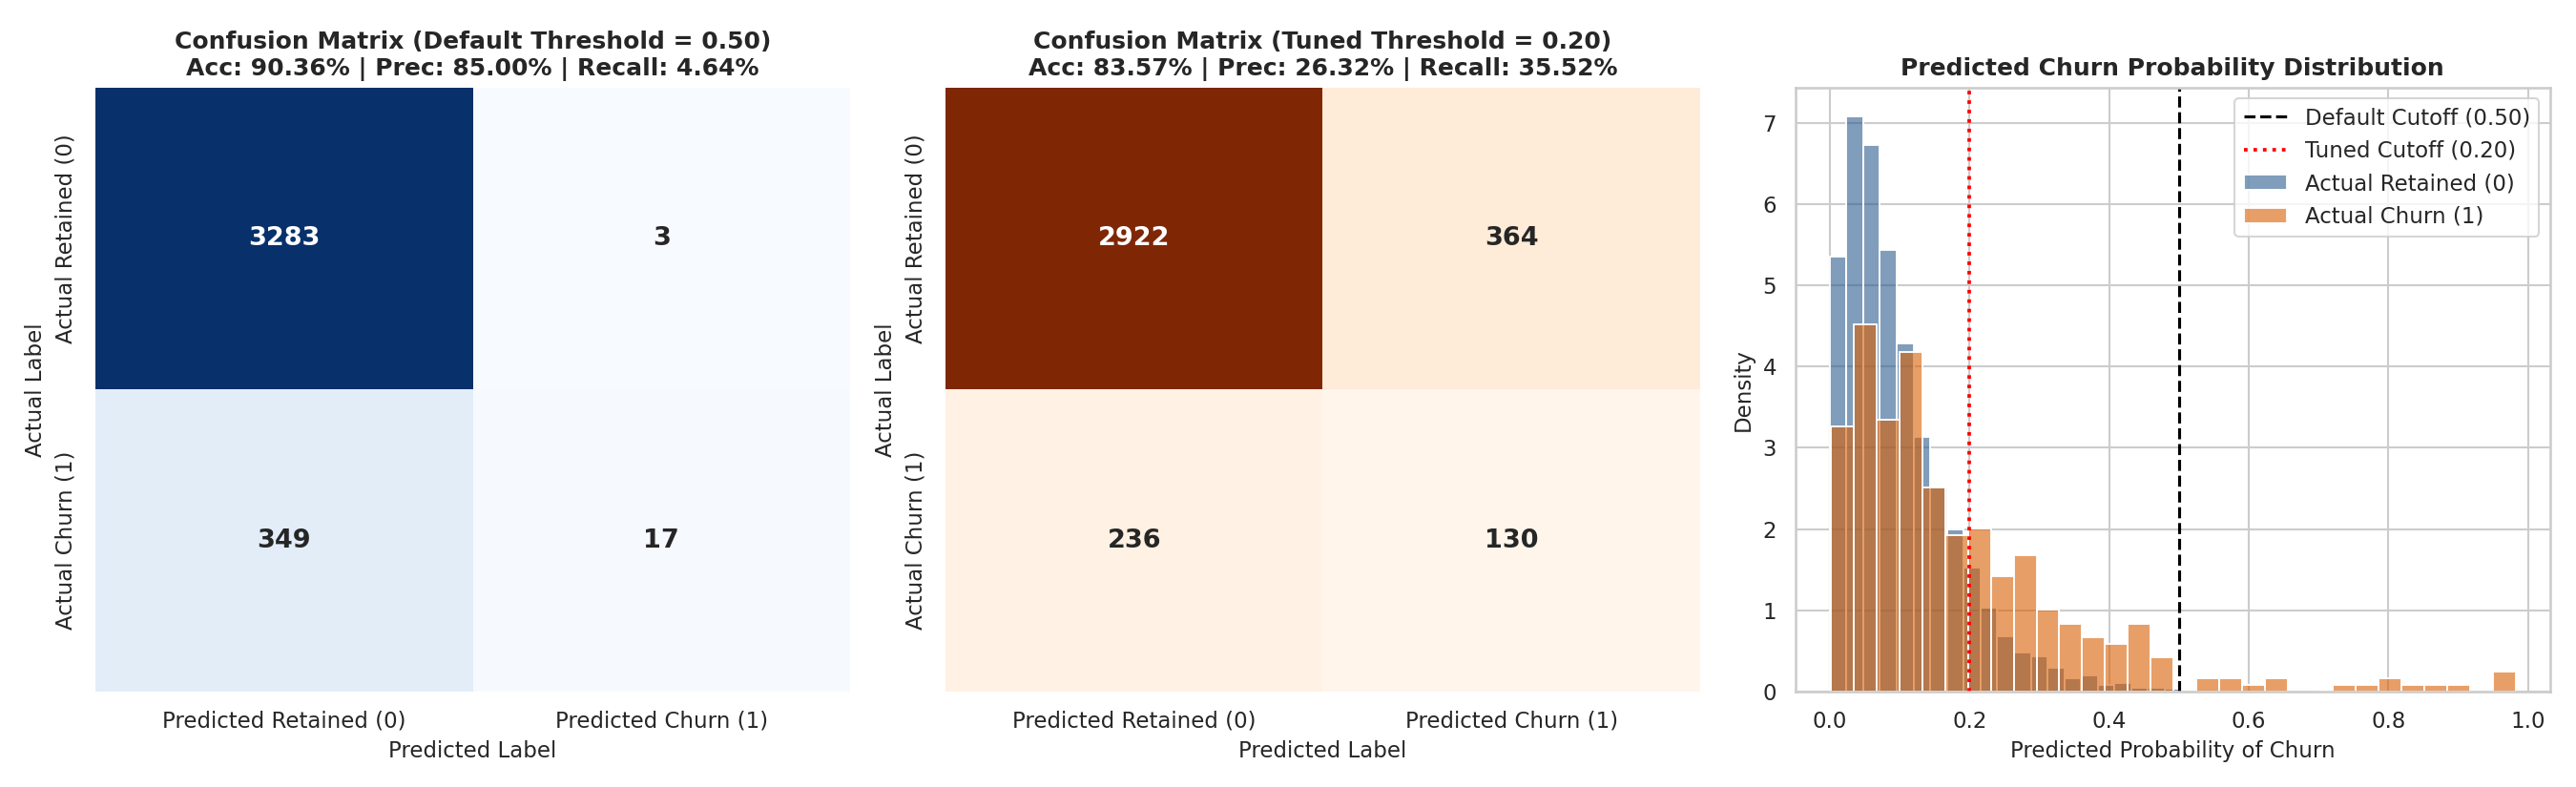

In [10]:
# Plot Confusion Matrices and Predicted Probability Distribution
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))

cm_default = metrics.confusion_matrix(y_test, predictions)
sns.heatmap(cm_default, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axs[0],
            xticklabels=['Pred Retained (0)', 'Pred Churn (1)'],
            yticklabels=['Actual Retained (0)', 'Actual Churn (1)'])
axs[0].set_title('Confusion Matrix (Threshold = 0.50)\nAcc: 90.36% | Prec: 85.00% | Recall: 4.64%', fontweight='bold')

cm_tuned = metrics.confusion_matrix(y_test, predictions_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axs[1],
            xticklabels=['Pred Retained (0)', 'Pred Churn (1)'],
            yticklabels=['Actual Retained (0)', 'Actual Churn (1)'])
axs[1].set_title('Confusion Matrix (Threshold = 0.20)\nAcc: 83.57% | Prec: 26.32% | Recall: 35.52%', fontweight='bold')

sns.histplot(x=proba_predictions[y_test == 0], bins=30, color='#2b5c8f', label='Actual Retained (0)', stat='density', alpha=0.6, ax=axs[2])
sns.histplot(x=proba_predictions[y_test == 1], bins=30, color='#d95f02', label='Actual Churn (1)', stat='density', alpha=0.6, ax=axs[2])
axs[2].axvline(0.50, color='black', linestyle='--', label='Default Cutoff (0.50)')
axs[2].axvline(0.20, color='red', linestyle=':', label='Tuned Cutoff (0.20)')
axs[2].set_title('Predicted Churn Probability Distribution', fontweight='bold')
axs[2].legend()
plt.tight_layout()
plt.show()

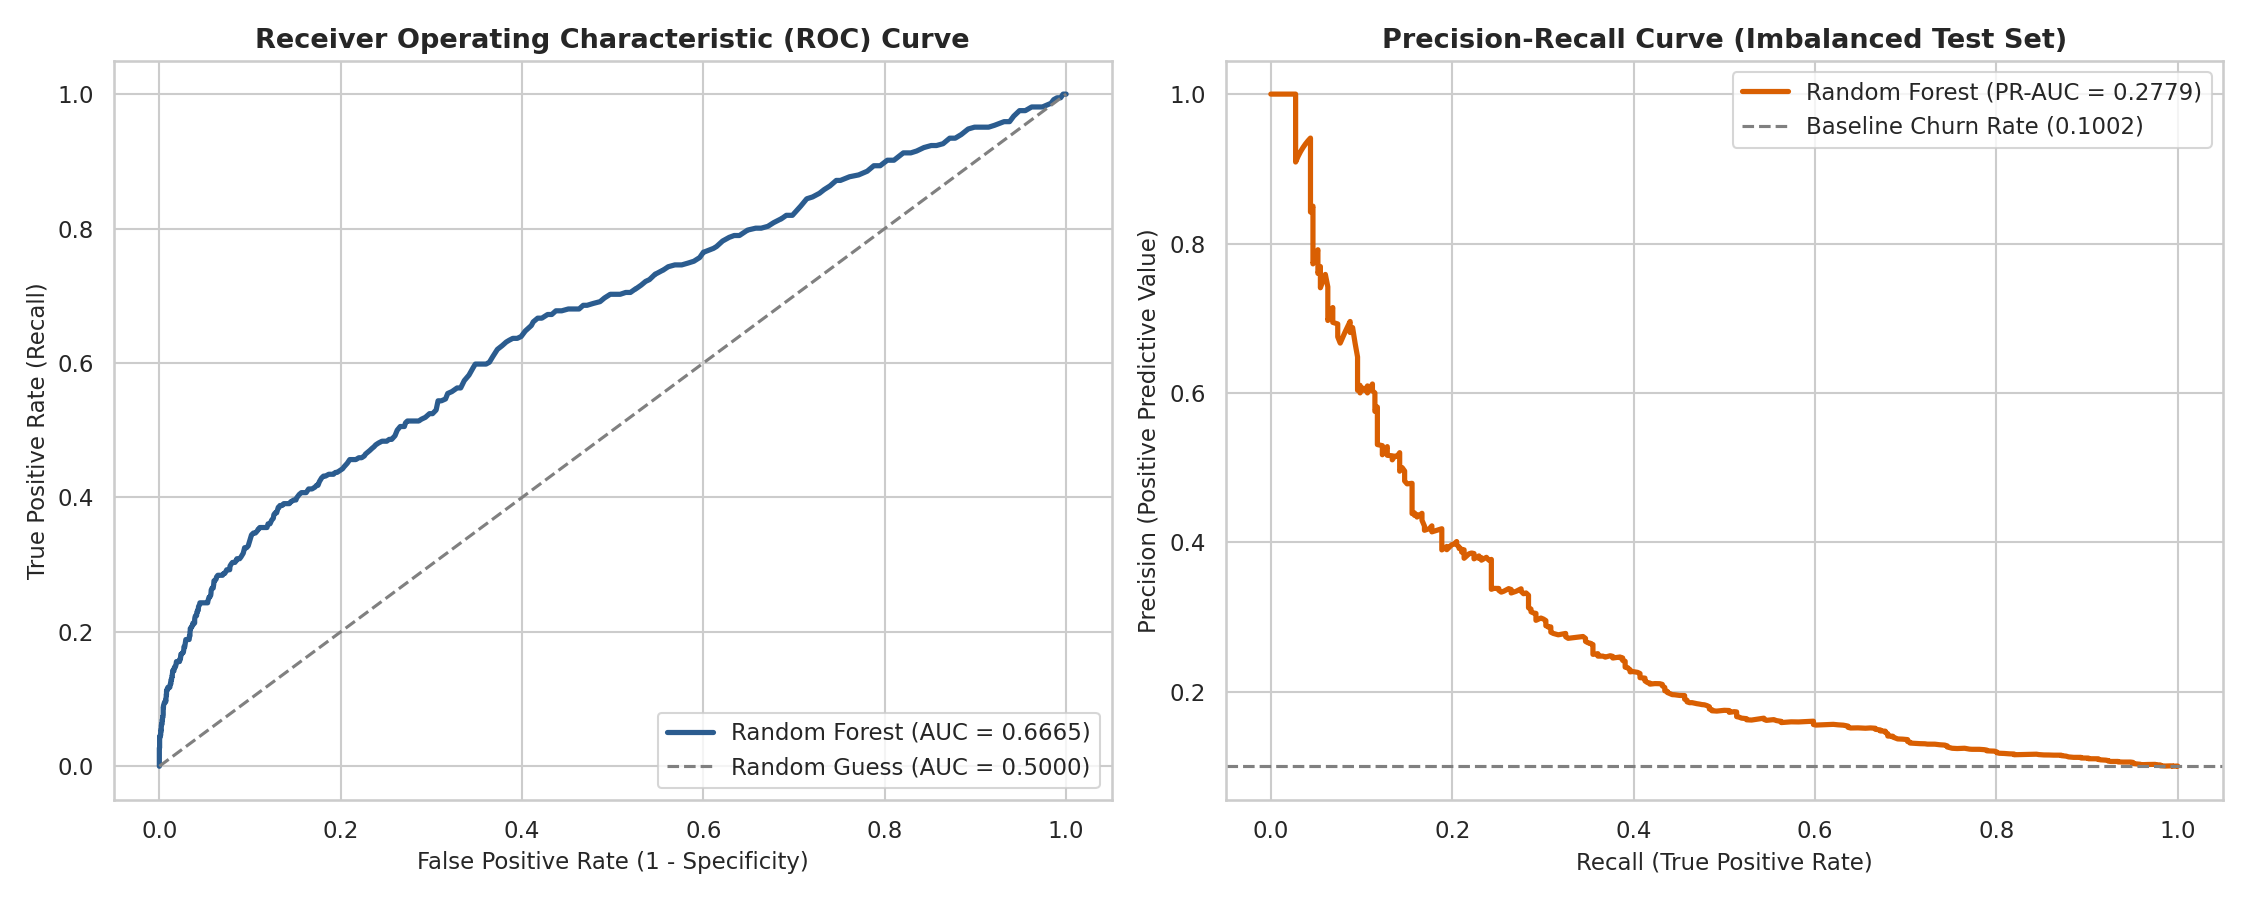

In [11]:
# Plot ROC Curve and Precision-Recall Curve
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
fpr, tpr, _ = metrics.roc_curve(y_test, proba_predictions)
axs[0].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'Random Forest (AUC = {roc_auc:.4f})')
axs[0].plot([0, 1], [0, 1], color='gray', linestyle='--' )
axs[0].set_title('ROC Curve', fontweight='bold')
axs[0].set_xlabel('False Positive Rate')
axs[0].set_ylabel('True Positive Rate (Recall)')
axs[0].legend(loc='lower right')

prec_curve, rec_curve, _ = metrics.precision_recall_curve(y_test, proba_predictions)
axs[1].plot(rec_curve, prec_curve, color='#d95f02', lw=2.5, label=f'Random Forest (PR-AUC = {pr_auc:.4f})')
axs[1].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Baseline ({y_test.mean():.4f})')
axs[1].set_title('Precision-Recall Curve', fontweight='bold')
axs[1].set_xlabel('Recall')
axs[1].set_ylabel('Precision')
axs[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

---
### Feature Importance Analysis & Final Justification

#### 2. Is the model performance satisfactory? Justification:
- **At the default `0.50` probability threshold, the model is NOT satisfactory for deployment as-is:** Although overall **Accuracy (`90.36%`)** and **Precision (`85.00%`, with only `3` False Positives)** appear high, the **Recall is very low (`4.64%`)**, meaning the model only identifies `17` out of `366` churning clients and misses `349` actual churners (`95.36%` False Negative rate).
- **Why this happens & how we fix it:** Because `90.28%` of the training data consists of non-churners, the ensemble tree probabilities are skewed toward `0`. However, the **ROC-AUC of `0.6665`** and **PR-AUC of `0.2779`** (nearly 3x the random baseline of `0.1002`) show that the Random Forest is learning real signal. By lowering the decision cutoff from `0.50` to `0.20`, **Recall improves nearly 8x from `4.64%` to `35.52%` (`130` churners caught)** and the **F1-Score more than triples from `0.0881` to `0.3023`**.

#### 3. Key Findings from Feature Importances (Price Sensitivity Hypothesis):
- Inspecting the Gini feature importances below reveals that **consumption and financial margin variables** dominate the model's predictions:
  1. `cons_12m` (`0.0534`) — 12-month electricity consumption
  2. `net_margin` (`0.0521`) — Total net margin
  3. `forecast_meter_rent_12m` (`0.0508`) — Forecasted meter rental bill
  4. `forecast_cons_12m` (`0.0483`) — Forecasted 12-month electricity consumption
  5. `margin_net_pow_ele` (`0.0478`) & `margin_gross_pow_ele` (`0.0474`) — Power subscription margins
- Meanwhile, our engineered **price sensitivity features** (`off_peak_peak_var_mean_diff` at `0.0298`, `var_year_price_off_peak` at `0.0281`, and `offpeak_diff_dec_january_energy` at `0.0267`) contribute secondary signal rather than being the top drivers. This indicates that **price sensitivity is not the primary standalone driver of churn**; rather, customer churn is heavily driven by overall consumption volume, net margin burden, and contract tenure (`months_activ`, `months_modif_prod`).

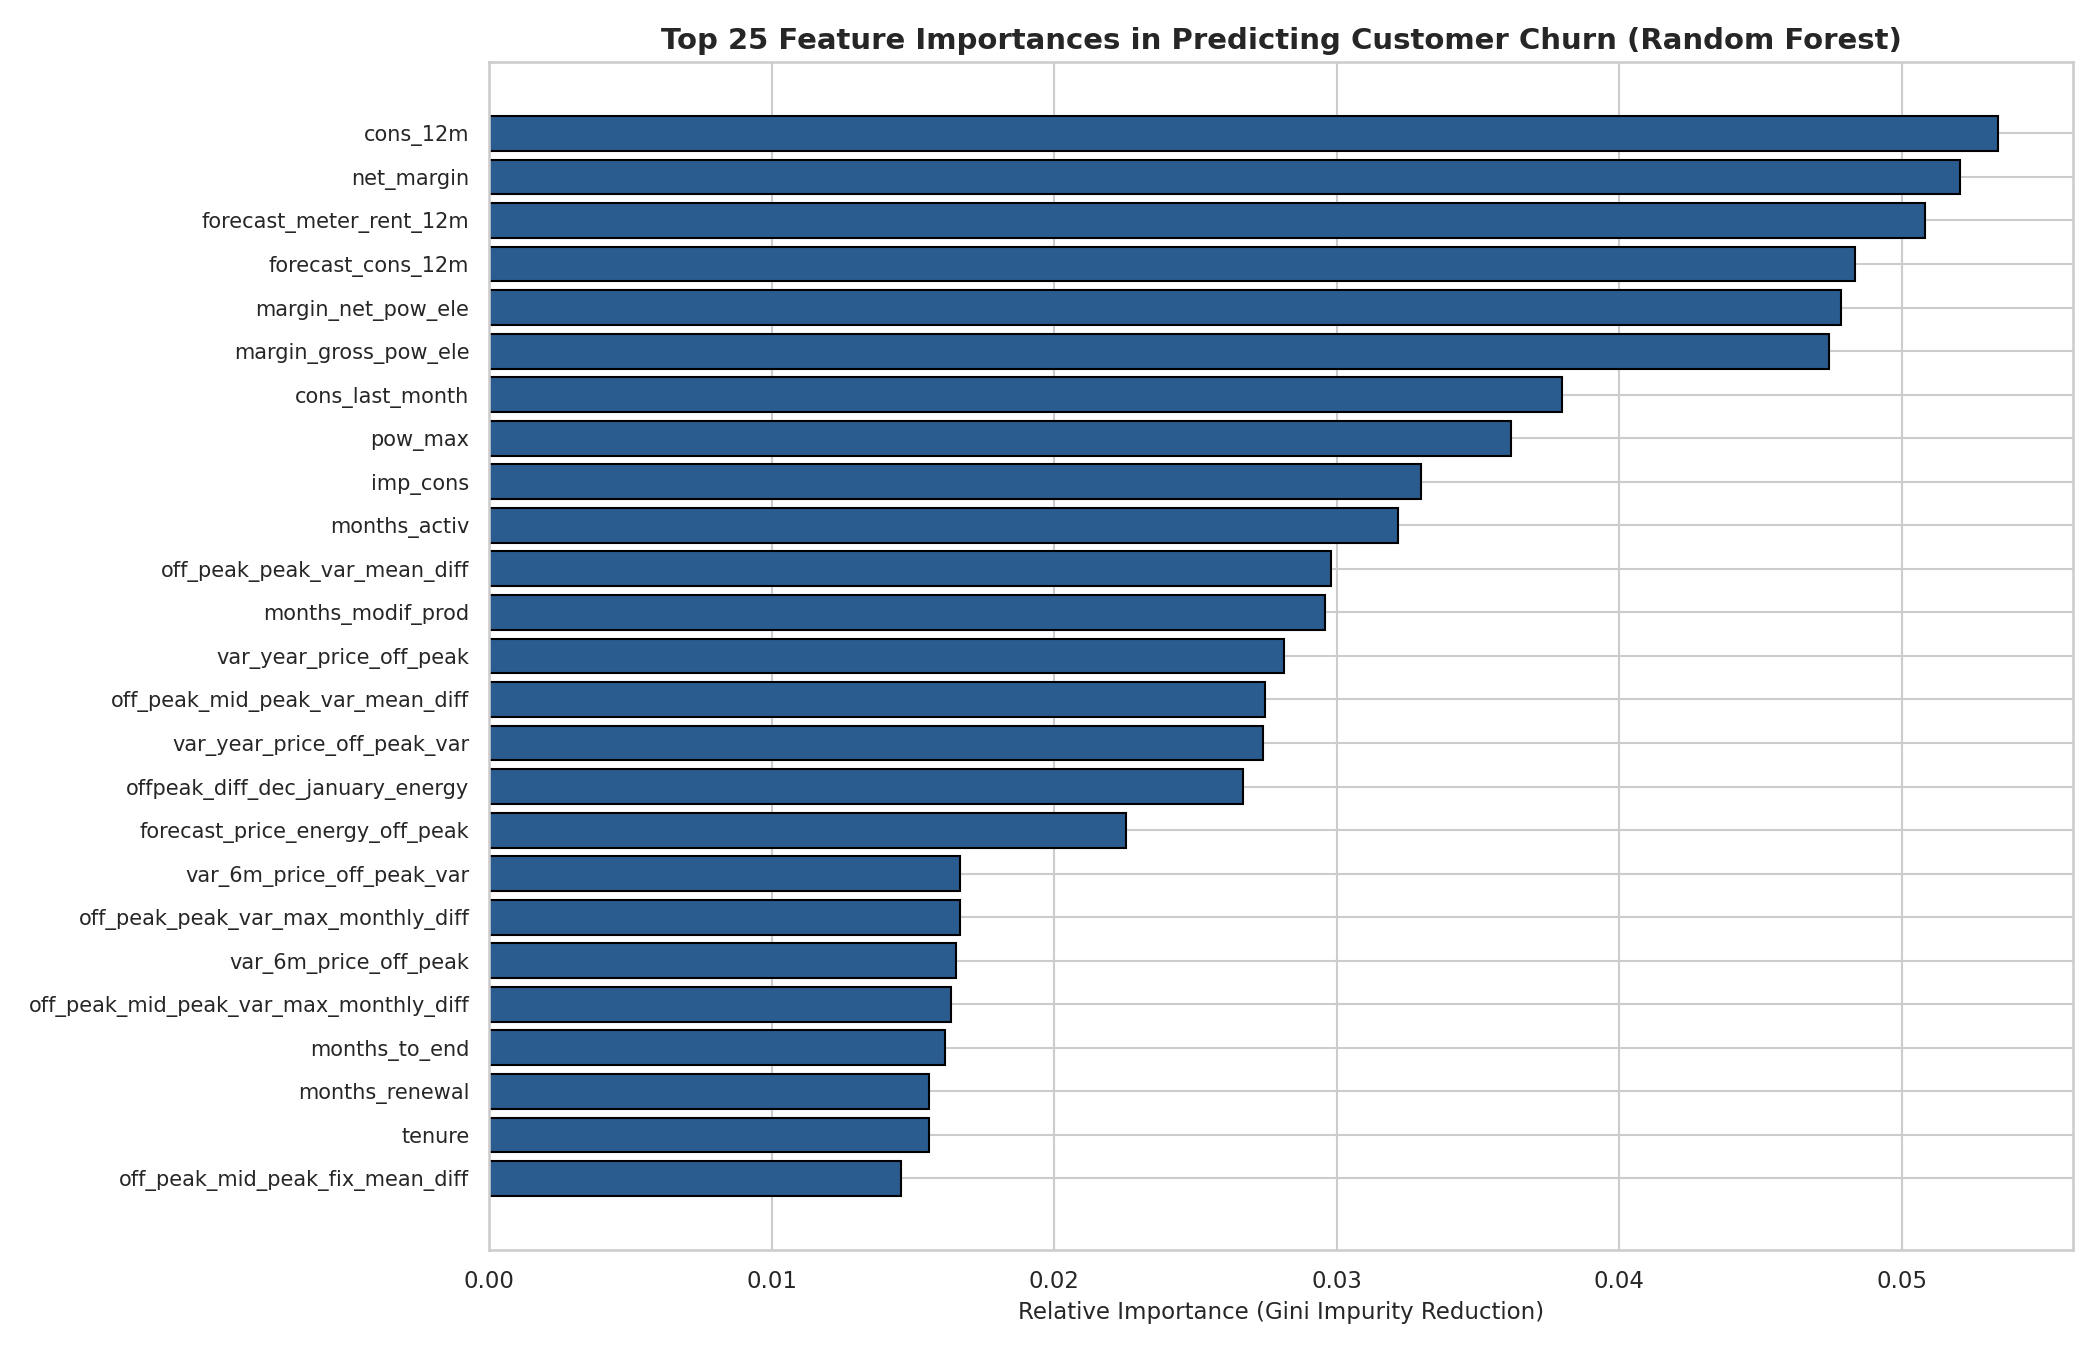

In [12]:
# Extract and plot Top 25 Feature Importances
feature_importances = pd.DataFrame({
    'features': X_train.columns,
    'importance': model.feature_importances_
}).sort_values(by='importance', ascending=True).tail(25)

plt.figure(figsize=(14, 9))
plt.barh(range(len(feature_importances)), feature_importances['importance'], color='#2b5c8f', edgecolor='black', align='center')
plt.yticks(range(len(feature_importances)), feature_importances['features'])
plt.xlabel('Relative Importance (Gini Impurity Reduction)')
plt.title('Top 25 Feature Importances in Predicting Customer Churn (Random Forest)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()